In [1]:
import numpy as np
from scipy.integrate import solve_ivp
import matplotlib.pyplot as plt

# Define system parameters
m1 = 1.6537
l1 = 0.343
r1 = 0.29
I1 = 0.039


m2 = 0.9982
l2 = 0.267
r2 = 0.175
I2 = 0.0081

a1 = m1*r1**2 + m2*l1**2 + I1
a2 = m2*r2**2 + I2
b = m2*l1*r2


# Define the Euler-Lagrange equations
def doublePendulum_ode(t, state):
    theta1, theta2, dtheta1, dtheta2 = state  # Generalized coordinates and velocities
    
    # Mass matrix
    M = np.array([[a1 + a2 + 2*b*np.cos(theta2),  a2 + np.cos(theta2)],
                  [a2 + b*np.cos(theta2), a2]])
    
    # Coriolis matrix
    C = np.array([[-b*np.sin(theta2)*dtheta2, -b*np.sin(theta2)*(dtheta1 + dtheta2)],
                  [b*np.sin(theta2)*dtheta1, 0]])


    # Gravity terms
    dVdq = np.array([[0],
                     [0]])
    
    # Solve for accelerations: M * [ddtheta1, ddtheta2]^T = -C * [dtheta1, dtheta2]^T - dVdq
    ddq = np.linalg.inv(M) @ (- C @ np.array([dtheta1, dtheta2]) - dVdq.flatten())
    
    return [dtheta1, dtheta2, ddq[0], ddq[1]]

# Function to compute total energy
def compute_total_energy(state):
    theta1, theta2, dtheta1, dtheta2 = state

    # Mass matrix
    M = np.array([[a1 + a2 + 2*b*np.cos(theta2),  a2 + np.cos(theta2)],
                  [a2 + b*np.cos(theta2), a2]])
    
    # Kinetic energy
    dtheta = np.array([dtheta1, dtheta2])
    T = 0.5 * dtheta @ M @ dtheta.T
    
    # Potential energy
    V = 0
    
    return T + V

# Function to compute momentum p = M * dtheta
def compute_momentum(state):
    theta1, theta2, dtheta1, dtheta2 = state
    
    # Mass matrix
    M = np.array([[a1 + a2 + 2*b*np.cos(theta2),  a2 + np.cos(theta2)],
                  [a2 + b*np.cos(theta2), a2]])
    
    # Compute momentum
    dtheta = np.array([dtheta1, dtheta2])
    p = M @ dtheta  # Generalized momentum
    
    return p

# Time parameters
t_span = (0, 5)  # Simulating for a longer time
t_eval = np.arange(t_span[0], t_span[1], 0.1)

# Number of simulations
num_simulations = 40

# Random initial conditions: theta1, theta2 ∈ [-π, π], dtheta1, dtheta2 ∈ [-1, 1]
initial_conditions = np.random.uniform(low=[-np.pi, -np.pi, -1.0, -1.0], high=[np.pi, np.pi, 1.0, 1.0], size=(num_simulations, 4))

# Dictionary to store trajectories
trajectories = {"time": t_eval, "states": []}

# Run simulations
for i, x0 in enumerate(initial_conditions):
    print(f"Running simulation {i+1}...")
    
    # Integrate the ODE using solve_ivp
    solution = solve_ivp(doublePendulum_ode, t_span, x0, method='RK45', t_eval=t_eval, rtol=1e-6, atol=1e-9)
    
    # Compute total energy and momentum for each time step
    total_energy = np.array([compute_total_energy(solution.y[:, j]) for j in range(len(solution.t))])
    momentum = np.array([compute_momentum(solution.y[:, j]) for j in range(len(solution.t))])
    
    # Store the trajectory
    trajectories["states"].append({
        "initial_condition": x0,
        "theta1": solution.y[0],  # θ1
        "theta2": solution.y[1],  # θ2
        "dtheta1": solution.y[2],  # ω1
        "dtheta2": solution.y[3],  # ω2
        "p1": momentum[:, 0],  # Momentum p1
        "p2": momentum[:, 1],  # Momentum p2
        "total_energy": total_energy  # Total energy
    })

# Save the trajectories for later use
np.save("double_pendulum_trajectories.npy", trajectories)

# Plot total energy over time for all simulations
plt.figure(figsize=(10, 6))
for i, traj in enumerate(trajectories["states"]):
    plt.plot(trajectories["time"], traj["total_energy"], label=f"Run {i+1}")
plt.title("Total Energy Over Time for All Simulations")
plt.xlabel("Time (s)")
plt.ylabel("Total Energy")
plt.legend()
plt.grid(True)
plt.show()

# Plot θ1 vs θ2 for all simulations
plt.figure(figsize=(10, 8))
for i, traj in enumerate(trajectories["states"]):
    plt.plot(traj["theta1"], traj["theta2"], label=f"Run {i+1}")
plt.title(r"$\theta_1$ vs $\theta_2$ for All Simulations")
plt.xlabel(r"$\theta_1$ [rad]")
plt.ylabel(r"$\theta_2$ [rad]")
plt.legend()
plt.grid(True)
plt.show()

print(f"Simulated {num_simulations} trajectories and saved to 'double_pendulum_trajectories.npy'.")


KeyboardInterrupt: 

Epoch 1/250, Loss: 0.119121, LR: 0.010000
Epoch 2/250, Loss: 0.022536, LR: 0.010000
Epoch 3/250, Loss: 0.008626, LR: 0.010000
Epoch 4/250, Loss: 0.004781, LR: 0.010000
Epoch 5/250, Loss: 0.003021, LR: 0.010000
Epoch 6/250, Loss: 0.002102, LR: 0.010000
Epoch 7/250, Loss: 0.001529, LR: 0.010000
Epoch 8/250, Loss: 0.001226, LR: 0.010000
Epoch 9/250, Loss: 0.000909, LR: 0.010000
Epoch 10/250, Loss: 0.000748, LR: 0.010000
Epoch 11/250, Loss: 0.000755, LR: 0.010000
Epoch 12/250, Loss: 0.000521, LR: 0.010000
Epoch 13/250, Loss: 0.000519, LR: 0.010000
Epoch 14/250, Loss: 0.000474, LR: 0.010000
Epoch 15/250, Loss: 0.000399, LR: 0.010000
Epoch 16/250, Loss: 0.000421, LR: 0.010000
Epoch 17/250, Loss: 0.000314, LR: 0.010000
Epoch 18/250, Loss: 0.000322, LR: 0.010000
Epoch 19/250, Loss: 0.000270, LR: 0.010000
Epoch 20/250, Loss: 0.000280, LR: 0.010000
Epoch 21/250, Loss: 0.000365, LR: 0.010000
Epoch 22/250, Loss: 0.000469, LR: 0.010000
Epoch 23/250, Loss: 0.000320, LR: 0.010000
Epoch 24/250, Loss: 

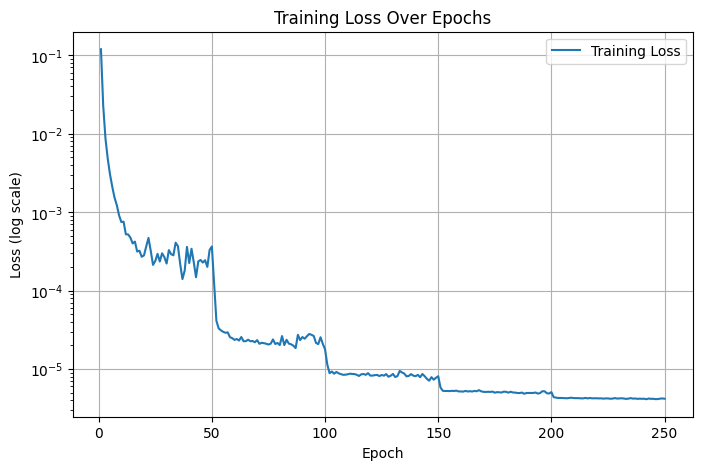

In [10]:
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt
from torchdiffeq import odeint_adjoint as odeint

# Load saved trajectories for the double pendulum
data = np.load("double_pendulum_trajectories.npy", allow_pickle=True).item()
t_eval = data["time"]  # Time points
state_trajectories = data["states"]  # List of dictionaries

# Prepare dataset: single state transitions (x_t -> x_t+1)
X, Y = [], []

for traj in state_trajectories:
    theta1 = traj["theta1"]
    theta2 = traj["theta2"]
    p1 = traj["p1"]
    p2 = traj["p2"]
    
    for t in range(len(t_eval) - 1):  # One-step transitions
        current_state = np.array([theta1[t], theta2[t], p1[t], p2[t]])
        next_state = np.array([theta1[t+1], theta2[t+1], p1[t+1], p2[t+1]])
        
        X.append(current_state)
        Y.append(next_state)

X = np.array(X, dtype=np.float32)
Y = np.array(Y, dtype=np.float32)

# Define the Hamiltonian Neural Network (HNN)
class HamiltonianNN(nn.Module):
    def __init__(self, input_dim=6, hidden_dim=200, output_dim=1):
        super(HamiltonianNN, self).__init__()
        self.fc1 = nn.Linear(input_dim, hidden_dim)
        self.fc2 = nn.Tanh()
        self.fc3 = nn.Linear(hidden_dim, output_dim)  # Output is scalar Hamiltonian H

    def forward(self, x):
        # Transform input: [theta1, theta2, p1, p2] -> [sin(theta1), cos(theta1), sin(theta2), cos(theta2), p1, p2]
        sin_theta1 = torch.sin(x[:, 0])
        cos_theta1 = torch.cos(x[:, 0])
        sin_theta2 = torch.sin(x[:, 1])
        cos_theta2 = torch.cos(x[:, 1])
        p1 = x[:, 2]
        p2 = x[:, 3]

        # Concatenate transformed features
        x_transformed = torch.stack([sin_theta1, cos_theta1, sin_theta2, cos_theta2, p1, p2], dim=1)

        # Pass through the network
        return self.fc3(self.fc2(self.fc1(x_transformed)))  # H(x)

# Define the learned Hamiltonian dynamics
class HamiltonianODEFunc(nn.Module):
    def __init__(self):
        super(HamiltonianODEFunc, self).__init__()
        self.hnn = HamiltonianNN()

    def forward(self, t, x):
        with torch.enable_grad():
            x = x.clone().detach().requires_grad_(True)  # Ensure x requires gradients
            H = self.hnn(x)  # Compute Hamiltonian
            
            # Compute gradients ∂H/∂x
            dH = torch.autograd.grad(outputs=H, inputs=x, grad_outputs=torch.ones_like(H), create_graph=True)[0]
            
            # Split gradients into positions and momenta
            dtheta1_dt = dH[:, 2]  # ∂H/∂p1
            dtheta2_dt = dH[:, 3]  # ∂H/∂p2
            dp1_dt = -dH[:, 0]  # -∂H/∂θ1
            dp2_dt = -dH[:, 1]  # -∂H/∂θ2

        return torch.stack([dtheta1_dt, dtheta2_dt, dp1_dt, dp2_dt], dim=1)

# Initialize HNN model
hamiltonian_ode_func = HamiltonianODEFunc()
optimizer = torch.optim.Adam(hamiltonian_ode_func.parameters(), lr=0.01)
criterion = nn.MSELoss()

# Learning rate scheduler
scheduler = optim.lr_scheduler.StepLR(optimizer, step_size=50, gamma=0.25)

# Training loop
batch_size = 32
num_epochs = 250
losses = []

for epoch in range(num_epochs):
    epoch_loss = 0.0
    indices = np.random.permutation(len(X))

    for batch_start in range(0, len(X), batch_size):
        batch_indices = indices[batch_start:batch_start + batch_size]
        
        # Ensure x0_batch requires gradients
        x0_batch = torch.tensor(X[batch_indices], dtype=torch.float32, requires_grad=True)
        x_target_batch = torch.tensor(Y[batch_indices], dtype=torch.float32)

        optimizer.zero_grad()

        # Ensure t_span is correctly formatted
        t_span = torch.tensor([0, t_eval[1] - t_eval[0]], dtype=torch.float32)
        
        # Solve ODE using odeint_adjoint
        x_pred_batch = odeint(hamiltonian_ode_func, x0_batch, t_span, rtol=1e-6, atol=1e-9)[-1]

        # Ensure x_pred_batch requires gradients
        x_pred_batch.requires_grad_(True)

        loss = criterion(x_pred_batch, x_target_batch)
        loss.backward()
        optimizer.step()

        epoch_loss += loss.item()

    avg_loss = epoch_loss / (len(X) // batch_size)
    losses.append(avg_loss)
    scheduler.step()

    print(f"Epoch {epoch+1}/{num_epochs}, Loss: {avg_loss:.6f}, LR: {scheduler.get_last_lr()[0]:.6f}")

# Save trained model
torch.save(hamiltonian_ode_func.state_dict(), "hnn_double_pendulum.pth")
print("Model saved as 'hnn_double_pendulum.pth'.")

# Plot training loss
plt.figure(figsize=(8, 5))
plt.plot(range(1, num_epochs+1), losses, label="Training Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss (log scale)")
plt.yscale("log")
plt.title("Training Loss Over Epochs")
plt.legend()
plt.grid(True)
plt.show()


C:\Users\Joel\AppData\Local\Temp\ipykernel_3308\197751499.py:48: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  hamiltonian_ode_func.load_state_dict(torch.load("hnn_double_pe

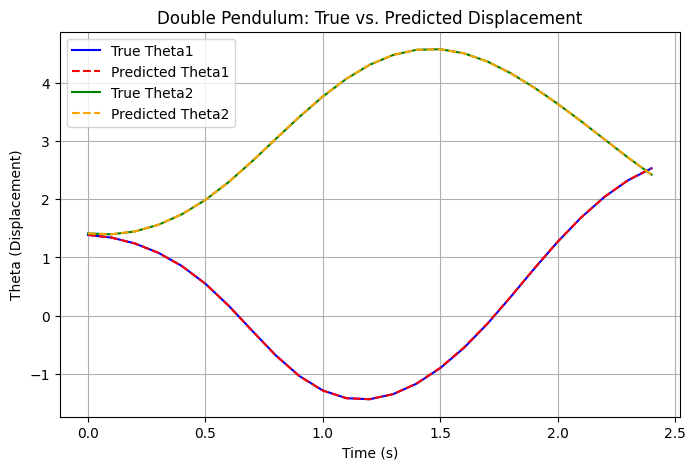

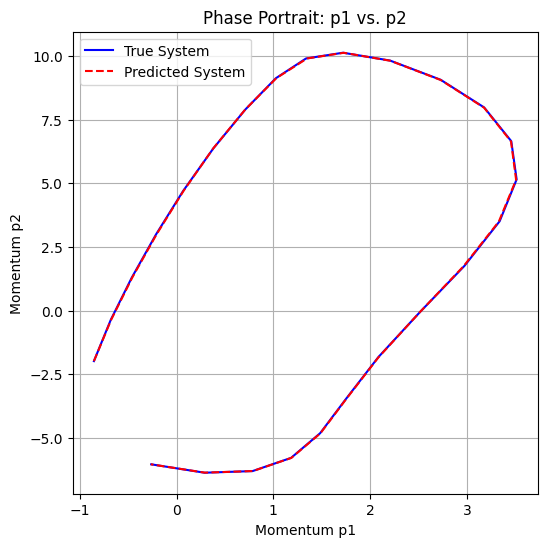

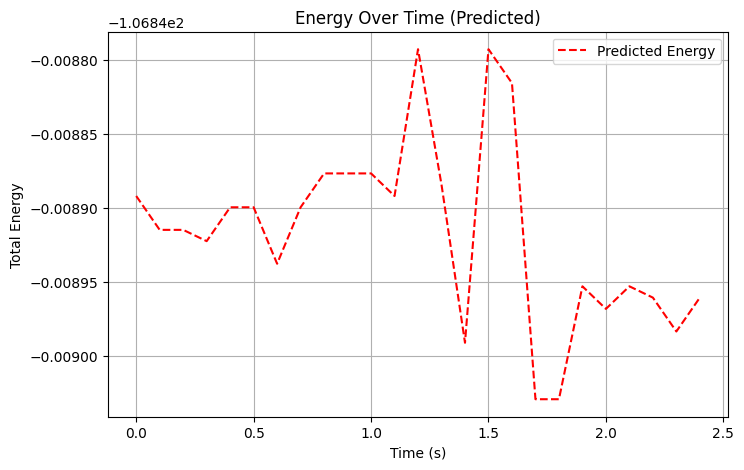

In [25]:
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from torchdiffeq import odeint_adjoint as odeint

# Define the Hamiltonian Neural Network (HNN)
class HamiltonianNN(nn.Module):
    def __init__(self, input_dim=6, hidden_dim=200, output_dim=1):
        super(HamiltonianNN, self).__init__()
        self.fc1 = nn.Linear(input_dim, hidden_dim)
        self.fc2 = nn.Tanh()
        self.fc3 = nn.Linear(hidden_dim, output_dim)  # Output is scalar Hamiltonian H

    def forward(self, x):
        # Transform input: [theta1, theta2, p1, p2] -> [sin(theta1), cos(theta1), sin(theta2), cos(theta2), p1, p2]
        sin_theta1 = torch.sin(x[:, 0])
        cos_theta1 = torch.cos(x[:, 0])
        sin_theta2 = torch.sin(x[:, 1])
        cos_theta2 = torch.cos(x[:, 1])
        p1 = x[:, 2]
        p2 = x[:, 3]

        # Concatenate transformed features
        x_transformed = torch.stack([sin_theta1, cos_theta1, sin_theta2, cos_theta2, p1, p2], dim=1)

        # Pass through the network
        return self.fc3(self.fc2(self.fc1(x_transformed)))  # H(x)

# Define Hamiltonian-based ODE function
class HamiltonianODEFunc(nn.Module):
    def __init__(self):
        super(HamiltonianODEFunc, self).__init__()
        self.hnn = HamiltonianNN()

    def forward(self, t, x):
        with torch.enable_grad():
            x = x.clone().detach().requires_grad_(True)
            H = self.hnn(x)
            dH = torch.autograd.grad(outputs=H, inputs=x, grad_outputs=torch.ones_like(H), create_graph=True)[0]
            dtheta1_dt, dtheta2_dt = dH[:, 2], dH[:, 3]  # dq/dt = dH/dp
            dp1_dt, dp2_dt = -dH[:, 0], -dH[:, 1]  # dp/dt = -dH/dq
        return torch.stack([dtheta1_dt, dtheta2_dt, dp1_dt, dp2_dt], dim=1)

# Load the trained model
hamiltonian_ode_func = HamiltonianODEFunc()
hamiltonian_ode_func.load_state_dict(torch.load("hnn_double_pendulum.pth"))
hamiltonian_ode_func.eval()

# Define system parameters
m1 = 1
l1 = 1 
lc1 = 0.5
Jl1 = 1

m2 = 1
l2 = 1 
lc2 = 0.5
Jl2 = 1

c1 = m2 * lc2**2 + m1 * l2**2 + Jl2
c2 = m1 * lc1**2 + Jl1
c3 = m1 * l2 * lc1
c4 = m2 * lc2 + m1 * l1
c5 = m1 * lc1

g = 9.8  # Gravitational acceleration

# Define the Euler-Lagrange equations
def doublePendulum_ode(t, state):
    theta1, theta2, dtheta1, dtheta2 = state  # Generalized coordinates and velocities
    
    # Mass matrix
    M = np.array([[c2, c2 + c3 * np.cos(theta1)],
                  [c2 + c3 * np.cos(theta1), c1 + c2 + 2 * c3 * np.cos(theta1)]])
    
    # Coriolis matrix
    C = np.array([[0, dtheta2 * c3 * np.sin(theta1)],
                  [-(dtheta1 + dtheta2) * c3 * np.sin(theta1), -dtheta1 * c3 * np.sin(theta1)]])

    # Gravity terms
    dVdq = np.array([[-c5 * g * np.sin(theta1 + theta2)],
                     [-c4 * g * np.sin(theta2) - c5 * g * np.sin(theta1 + theta2)]])
    
    # Solve for accelerations: M * [ddtheta1, ddtheta2]^T = -C * [dtheta1, dtheta2]^T - dVdq
    ddq = np.linalg.inv(M) @ (- C @ np.array([dtheta1, dtheta2]) - dVdq.flatten())
    
    return [dtheta1, dtheta2, ddq[0], ddq[1]]

# Function to compute momentum p = M * dtheta
def compute_momentum(state):
    theta1, theta2, dtheta1, dtheta2 = state
    
    # Mass matrix
    M = np.array([[c2, c2 + c3 * np.cos(theta1)],
                  [c2 + c3 * np.cos(theta1), c1 + c2 + 2 * c3 * np.cos(theta1)]])
    
    # Compute momentum
    dtheta = np.array([dtheta1, dtheta2])
    p = M @ dtheta  # Generalized momentum
    
    return p

# Define a new initial condition
new_initial_condition_velocity = np.random.uniform(low=[-np.pi, -np.pi, -1, -1], high=[np.pi, np.pi, 1, 1])
t_span = (0, 2.5)
t_eval = np.arange(t_span[0], t_span[1], 0.1)

# Solve the true system
true_solution = solve_ivp(doublePendulum_ode, t_span, new_initial_condition_velocity, t_eval=t_eval, rtol=1e-6, atol=1e-9)
true_states = true_solution.y
true_momentum = np.array([compute_momentum(true_solution.y[:, j]) for j in range(len(true_solution.t))])

# Solve the learned Hamiltonian Neural ODE
t_tensor = torch.tensor(t_eval, dtype=torch.float32)
new_initial_condition_momentum = np.concatenate((new_initial_condition_velocity[:2], true_momentum[0,:]))
x0_tensor = torch.tensor(new_initial_condition_momentum, dtype=torch.float32).unsqueeze(0)
predicted_states = odeint(hamiltonian_ode_func, x0_tensor, t_tensor, rtol=1e-6, atol=1e-9)
predicted_states = predicted_states.detach().numpy().squeeze()

# Plot theta1 and theta2
plt.figure(figsize=(8, 5))
plt.plot(t_eval, true_states[0], label="True Theta1", linestyle="-", color="blue")
plt.plot(t_eval, predicted_states[:, 0], label="Predicted Theta1", linestyle="--", color="red")
plt.plot(t_eval, true_states[1], label="True Theta2", linestyle="-", color="green")
plt.plot(t_eval, predicted_states[:, 1], label="Predicted Theta2", linestyle="--", color="orange")
plt.xlabel("Time (s)")
plt.ylabel("Theta (Displacement)")
plt.title("Double Pendulum: True vs. Predicted Displacement")
plt.legend()
plt.grid(True)
plt.show()

# Phase plot (theta1, p1) and (theta2, p2)
plt.figure(figsize=(6, 6))
plt.plot(true_momentum[:, 0], true_momentum[:, 1], label="True System", linestyle="-", color="blue")
plt.plot(predicted_states[:, 2], predicted_states[:, 3], label="Predicted System", linestyle="--", color="red")
plt.xlabel("Momentum p1")
plt.ylabel("Momentum p2")
plt.title("Phase Portrait: p1 vs. p2")
plt.legend()
plt.grid(True)
plt.show()

# Compute and plot energy
predicted_energies = [hamiltonian_ode_func.hnn(torch.tensor(state, dtype=torch.float32).unsqueeze(0)).item()
                      for state in predicted_states]
plt.figure(figsize=(8, 5))
plt.plot(t_eval, predicted_energies, label="Predicted Energy", linestyle="--", color="red")
plt.xlabel("Time (s)")
plt.ylabel("Total Energy")
plt.title("Energy Over Time (Predicted)")
plt.legend()
plt.grid(True)
plt.show()
